# 07: Experimental comparison (Phase 8)

This notebook covers Experiments A–E and the final performance summary, from `python main.py evaluate`.

In [1]:
import sys, os, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 220, 'display.max_columns', 40, 'display.max_colwidth', 60)
OUT = ROOT / 'data/outputs'
for f in ['experiment_warehouse_comparison','experiment_routing_comparison','forecast_impact_comparison']:
    print(f); display(pd.read_csv(OUT / f'{f}.csv'))

experiment_warehouse_comparison


,method,network,n_open,opening_cost,transport_cost,handling_cost,cflp_objective_excl_handling,total_cost,avg_distance_km_order_weighted,max_distance_km,mean_utilization,max_utilization,capacity_overload_units,unserved_units,unserved_zones,closed_warehouses_serving,feasible,orders_per_week,units_per_week,runtime_s,gap_vs_cflp_pct,solver_termination,solver_relative_gap,ga_runs,ga_total_cost_mean,ga_total_cost_std,ga_runs_matching_cflp,search_space,random_best_total,random_worst_total,random_feasible_share,cost_reduction_vs_k-means_pct,cost_reduction_vs_random_pct,cost_reduction_of_cflp_vs_this_pct
0,CFLP (exact MILP),CONUS,6.0,9000.0,9348.360207,148.903802,18348.360207,18497.264009,334.467270,1691.032490,0.620433,0.911040,0.0,0.0,0.0,0.0,True,279.5,297.807605,0.832574,0.000000,optimal,0.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.847401,38.583613,0.000000
1,Genetic Algorithm (best of seeds),CONUS,6.0,9000.0,9455.735019,148.903802,18455.735019,18604.638822,338.308945,1738.647221,0.620433,0.911040,0.0,0.0,0.0,0.0,True,279.5,297.807605,71.995797,0.580490,NaN,NaN,5.0,18813.072508,122.851384,0.0,3.231939e+09,NaN,NaN,NaN,0.271830,38.227097,0.577140
2,K-Means (k=6),CONUS,6.0,9000.0,9506.445826,148.903802,18506.445826,18655.349629,340.123285,1691.032490,0.620433,0.929542,0.0,0.0,0.0,0.0,True,279.5,297.807605,0.475909,0.854643,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,38.058722,0.847401
3,"Random (k=6, mean of 30)",CONUS,6.0,9000.0,20968.895290,148.903802,29968.895290,30117.799092,750.228812,2708.684025,0.620433,0.999726,0.0,0.0,0.0,0.0,True,279.5,297.807605,24.571040,62.822994,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22818.159558,44270.944230,1.0,-61.443230,0.000000,38.583613
4,CFLP (exact MILP),Puerto Rico,2.0,2400.0,21.759655,87.750000,2421.759655,2509.509655,1.239866,143.972671,0.877500,0.942500,0.0,0.0,0.0,0.0,True,175.5,175.500000,0.053492,0.000000,optimal,1.251524e-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.734050,26.075421,0.000000
5,Genetic Algorithm (best of seeds),Puerto Rico,2.0,2400.0,21.759655,87.750000,2421.759655,2509.509655,1.239866,143.972671,0.877500,0.942500,0.0,0.0,0.0,0.0,True,175.5,175.500000,1.643898,0.000000,NaN,NaN,5.0,2527.351719,35.684129,4.0,1.525000e+04,NaN,NaN,NaN,21.734050,26.075421,0.000000
6,K-Means (k=2),Puerto Rico,2.0,2400.0,718.637534,87.750000,3118.637534,3206.387534,40.948008,143.972671,0.877500,0.960000,0.0,0.0,0.0,0.0,True,175.5,175.500000,0.069268,27.769484,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,5.546947,21.734050
7,"Random (k=2, mean of 30)",Puerto Rico,2.0,2400.0,906.939126,87.750000,3306.939126,3394.689126,51.677443,133.550396,0.877500,0.959917,0.0,0.0,0.0,0.0,True,175.5,175.500000,1.537942,35.273005,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2630.487249,4950.262287,1.0,-5.872702,0.000000,26.075421


experiment_routing_comparison


,network,method,vehicles,total_distance_km,total_duration_h,total_route_cost,packages,mean_utilization_pct,capacity_used,capacity_available,fleet_utilization_pct,capacity_violations,route_length_violations,fleet_violations,unserved_stops,unserved_packages,all_feasible,runtime_s,distance_method,distance_reduction_vs_nearest_neighbor_pct,time_reduction_vs_nearest_neighbor_pct,route_cost_reduction_vs_nearest_neighbor_pct,distance_reduction_vs_ortools_standard_pct,time_reduction_vs_ortools_standard_pct,route_cost_reduction_vs_ortools_standard_pct
0,CONUS,nearest_neighbor,13,38635.491,617.725503,54078.628564,278,71.282051,278,390,71.282051,0,5,0,0,0,False,0.001035,haversine_circuity (approximate road km; not a road-netw...,0.000000,0.000000,0.000000,-22.081600,-21.071755,-21.791506
1,CONUS,ortools_gls,16,31610.439,509.647779,44351.633487,278,57.916667,278,480,57.916667,0,0,0,0,0,True,60.010434,haversine_circuity (approximate road km; not a road-netw...,18.182898,17.496076,17.986764,0.116373,0.111051,0.114845
2,CONUS,ortools_standard,16,31647.268,510.214379,44402.627487,278,57.916667,278,480,57.916667,0,0,0,0,0,True,0.167832,haversine_circuity (approximate road km; not a road-netw...,18.087574,17.404352,17.892468,0.000000,0.000000,0.000000
3,Puerto Rico,nearest_neighbor,7,173.579,6.172808,327.899208,175,83.333333,175,210,83.333333,0,0,0,0,0,True,0.000131,haversine_circuity (approximate road km; not a road-netw...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,Puerto Rico,ortools_gls,7,173.579,6.172808,327.899208,175,83.333333,175,210,83.333333,0,0,0,0,0,True,20.001827,haversine_circuity (approximate road km; not a road-netw...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5,Puerto Rico,ortools_standard,7,173.579,6.172808,327.899208,175,83.333333,175,210,83.333333,0,0,0,0,0,True,0.009609,haversine_circuity (approximate road km; not a road-netw...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


forecast_impact_comparison


,network,scenario,planned_orders_per_week,planned_units_per_week,realised_orders_per_week,realised_units_per_week,warehouses_opened,open_warehouses,planned_total_cost,planned_unserved_units,realised_opening_cost,realised_transport_cost,realised_total_cost,realised_mean_utilization,realised_max_utilization,realised_unserved_units,capacity_violation_units_if_plan_kept,transport_cost_if_plan_kept,regret_vs_oracle,regret_vs_oracle_pct,plan_runtime_s,plan_solver_termination,plan_best_objective_incl_penalty,plan_lower_bound,plan_relative_gap,plan_proven_optimal,plan_bound_note,recourse_termination,recourse_relative_gap,forecast_cost_reduction_vs_historical_pct
0,CONUS,1: historical average demand,229.441500,1461.618200,278.230769,278.230769,12,WH-US-02;WH-US-03;WH-US-04;WH-US-05;WH-US-08;WH-US-09;WH...,27859.462476,503.7276,18000.0,8237.948272,26377.063656,0.289824,0.500962,0.0,0.000000,11898.796875,7857.447705,42.427703,122.185757,maxTimeLimit,5.064657e+06,5.035900e+06,5.677842e-03,False,NaN,optimal,0.000000e+00,29.505491
1,CONUS,2: selected forecast demand,279.250200,330.575446,278.230769,278.230769,6,WH-US-01;WH-US-03;WH-US-05;WH-US-14;WH-US-31;WH-US-37,18491.920002,0.0000,9000.0,9455.266123,18594.381508,0.579647,0.917308,0.0,0.000000,9540.962360,74.765557,0.403710,3.631476,optimal,1.832663e+04,1.832650e+04,7.217858e-06,True,NaN,optimal,0.000000e+00,29.505491
2,CONUS,oracle: realised demand (perfect information),278.230769,278.230769,278.230769,278.230769,6,WH-US-01;WH-US-03;WH-US-05;WH-US-14;WH-US-17;WH-US-31,18519.615951,0.0000,9000.0,9380.500566,18519.615951,0.579647,0.870192,0.0,0.000000,9380.500566,0.000000,0.000000,2.948450,optimal,1.838050e+04,1.838050e+04,1.805085e-13,True,NaN,optimal,1.805085e-13,29.505491
3,Puerto Rico,1: historical average demand,146.550900,935.571300,175.461538,175.461538,2,WH-PR-03;WH-PR-13,2477.749813,826.6938,2400.0,556.994032,3044.724802,0.877308,0.959231,0.0,74.153846,66.826487,537.655436,21.445575,0.390639,optimal,8.269361e+06,NaN,NaN,True,CBC reports optimal; parsed lower bound 5.36055e+06 inco...,optimal,1.868513e-13,-21.607762
4,Puerto Rico,2: selected forecast demand,170.250000,211.250000,175.461538,175.461538,3,WH-PR-01;WH-PR-03;WH-PR-05,3721.996352,0.0000,3600.0,14.890935,3702.621704,0.584872,0.935385,0.0,0.000000,18.361035,1195.552339,47.687246,6.791289,optimal,3.616371e+03,3.616371e+03,6.149022e-13,True,NaN,optimal,3.274531e-13,-21.607762
5,Puerto Rico,oracle: realised demand (perfect information),175.461538,175.461538,175.461538,175.461538,2,WH-PR-03;WH-PR-05,2507.069366,0.0000,2400.0,19.338597,2507.069366,0.877308,0.936923,0.0,0.000000,19.338597,0.000000,0.000000,0.080564,optimal,2.419339e+03,2.419339e+03,1.575698e-12,True,NaN,optimal,1.575698e-12,-21.607762


In [2]:
display(pd.read_csv(OUT / 'sensitivity_analysis.csv')[['experiment','network','parameter','value','n_open','total_cost','transport_cost','unserved_units','feasible','vehicles','total_distance_km']])
display(pd.read_csv(OUT / 'robustness_analysis.csv'))

,experiment,network,parameter,value,n_open,total_cost,transport_cost,unserved_units,feasible,vehicles,total_distance_km
0,warehouse,CONUS,capacity_multiplier,0.6,8.0,20478.674578,8329.770775,0.0,True,NaN,NaN
1,warehouse,CONUS,capacity_multiplier,0.8,6.0,18753.478122,9604.574320,0.0,True,NaN,NaN
2,warehouse,CONUS,capacity_multiplier,1.0,6.0,18497.264009,9348.360207,0.0,True,NaN,NaN
3,warehouse,CONUS,capacity_multiplier,1.5,5.0,18448.740173,10799.836370,0.0,True,NaN,NaN
4,warehouse,CONUS,capacity_multiplier,2.0,5.0,18448.740173,10799.836370,0.0,True,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
74,routing,Puerto Rico,vehicles_per_depot,2.0,NaN,NaN,NaN,NaN,False,4.0,173.579
75,routing,Puerto Rico,vehicles_per_depot,3.0,NaN,NaN,NaN,NaN,False,6.0,173.579
76,routing,Puerto Rico,vehicles_per_depot,4.0,NaN,NaN,NaN,NaN,True,7.0,173.579
77,routing,Puerto Rico,vehicles_per_depot,6.0,NaN,NaN,NaN,NaN,True,7.0,173.579


,network,demand_change,orders_per_week,units_per_week,warehouses,capacity_overload_if_allocation_kept,max_utilization_if_allocation_kept,reallocated_total_cost,reallocated_transport_cost,reallocated_max_utilization,unserved_units,warehouse_plan_feasible,reallocation_termination,reallocation_relative_gap,route_vehicles,route_distance_km,route_cost,route_unserved_packages,route_feasible,total_operating_cost
0,CONUS,-0.2,223.60,238.246084,6,0.000000,0.728832,16597.811207,7478.688165,0.728832,0.000,True,optimal,2.655848e-13,15,30483.866,42758.429846,0,True,59356.241053
1,CONUS,-0.1,251.55,268.026844,6,0.000000,0.819936,17547.537608,8413.524186,0.819936,0.000,True,optimal,0.000000e+00,16,30605.473,42926.808769,0,True,60474.346377
2,CONUS,0.0,279.50,297.807605,6,0.000000,0.911040,18497.264009,9348.360207,0.911040,0.000,True,optimal,0.000000e+00,16,31631.068,44380.196718,0,True,62877.460727
3,CONUS,0.1,307.45,327.588365,6,0.171535,1.002144,19447.293772,10283.499589,0.999982,0.000,True,optimal,5.164486e-06,18,32268.394,45304.314769,0,True,64751.608541
4,CONUS,0.2,335.40,357.369126,6,9.676750,1.093248,20528.993516,11350.308953,0.999788,0.000,True,optimal,0.000000e+00,18,32507.194,45668.294256,0,True,66197.287773
5,Puerto Rico,-0.2,140.40,140.400000,2,0.000000,0.754000,2487.607724,17.407724,0.754000,0.000,True,optimal,1.830346e-12,6,173.579,323.732542,0,True,2811.340265
6,Puerto Rico,-0.1,157.95,157.950000,2,0.000000,0.848250,2498.558689,19.583689,0.848250,0.000,True,optimal,1.540581e-12,6,173.579,323.732542,0,True,2822.291231
7,Puerto Rico,0.0,175.50,175.500000,2,0.000000,0.942500,2509.509655,21.759655,0.942500,0.000,True,optimal,1.251524e-12,7,173.579,327.899208,0,True,2837.408863
8,Puerto Rico,0.1,193.05,193.050000,2,3.675000,1.036750,2469.448120,23.935620,0.893750,102.025,False,optimal,2.390519e-15,7,308.213,555.012792,0,True,3024.460912
9,Puerto Rico,0.2,210.60,210.600000,2,13.100000,1.131000,2475.761586,26.111586,0.975000,111.300,False,optimal,1.461159e-15,8,308.213,559.179458,0,True,3034.941044


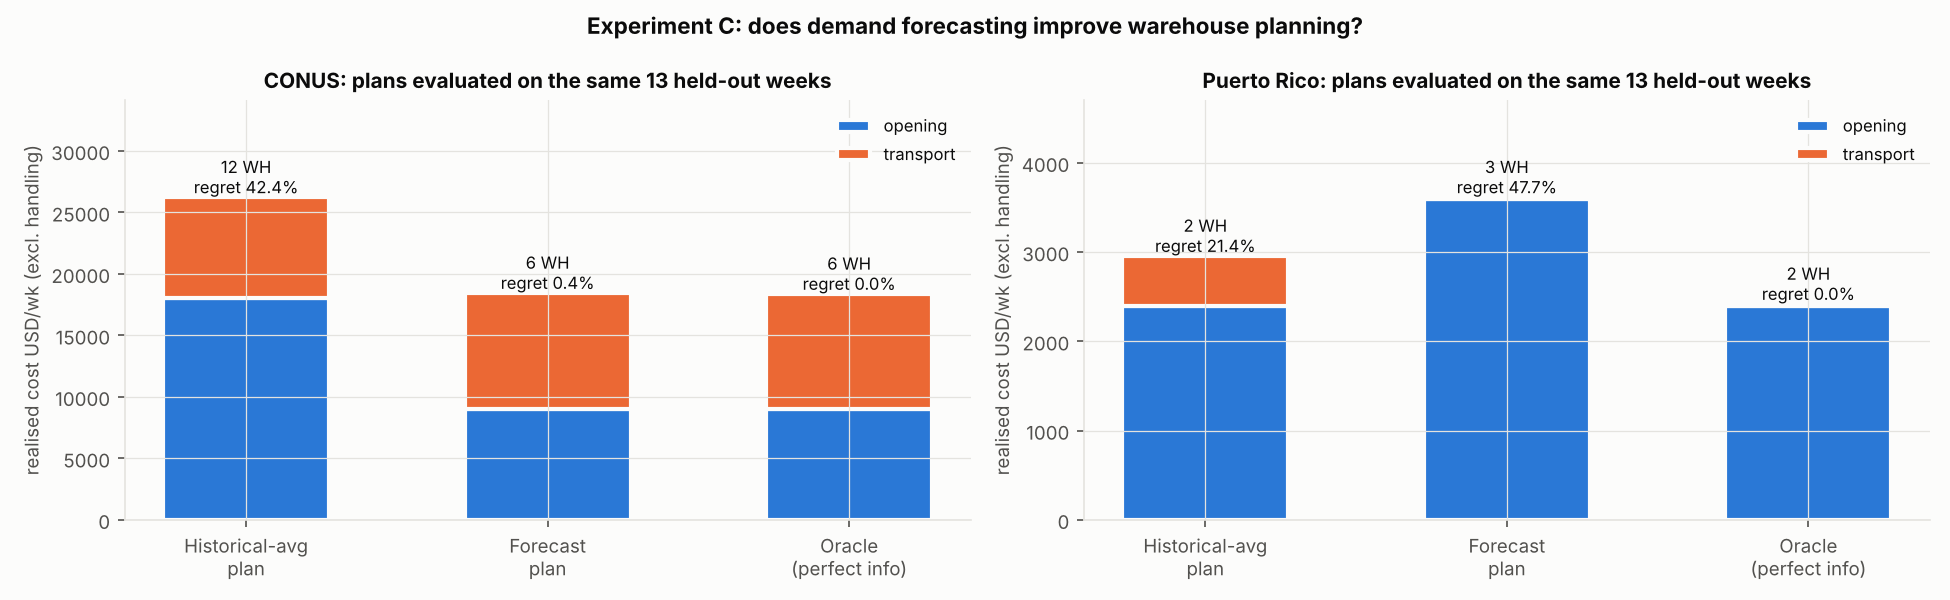

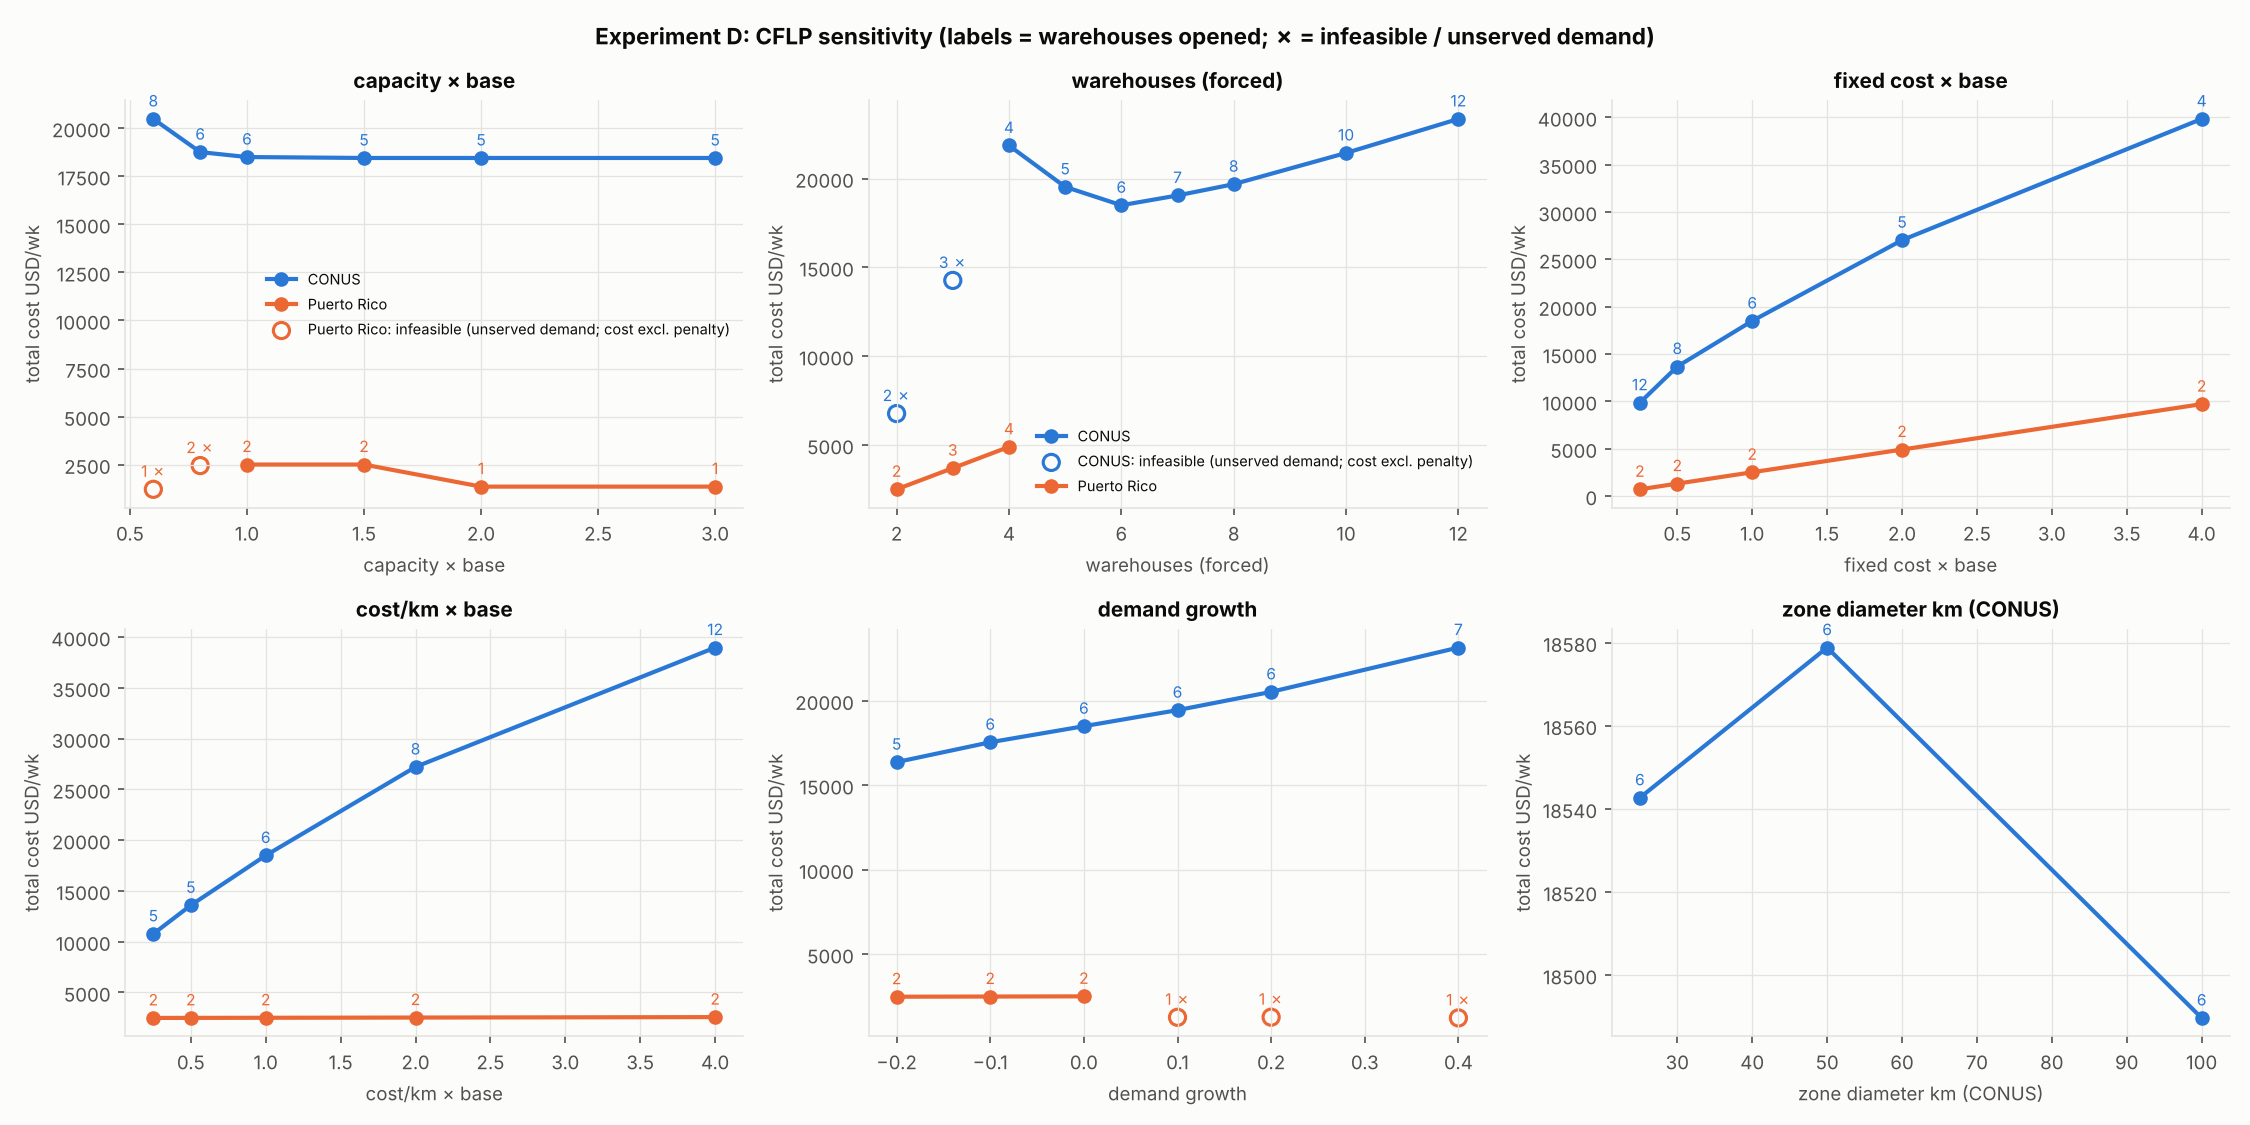

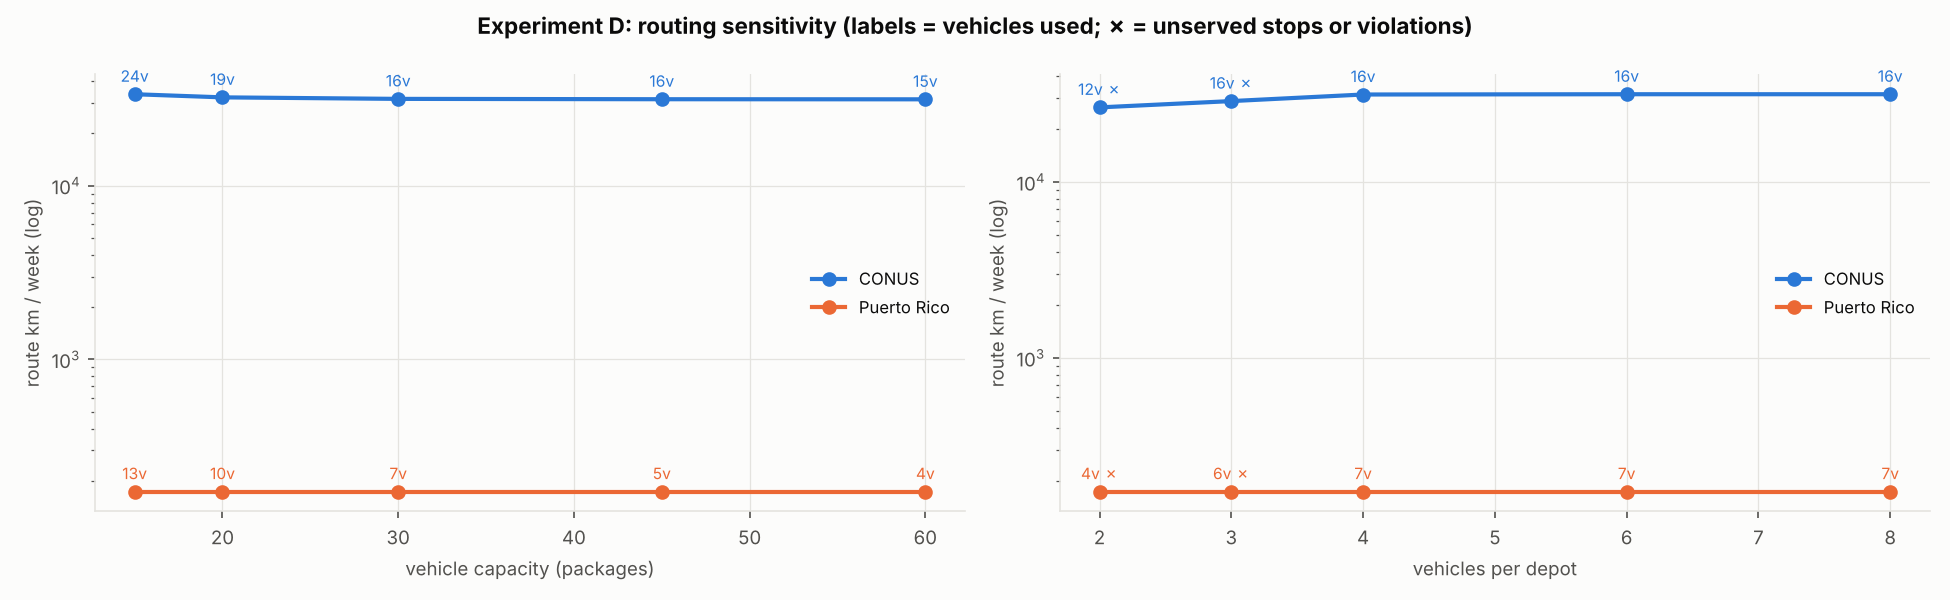

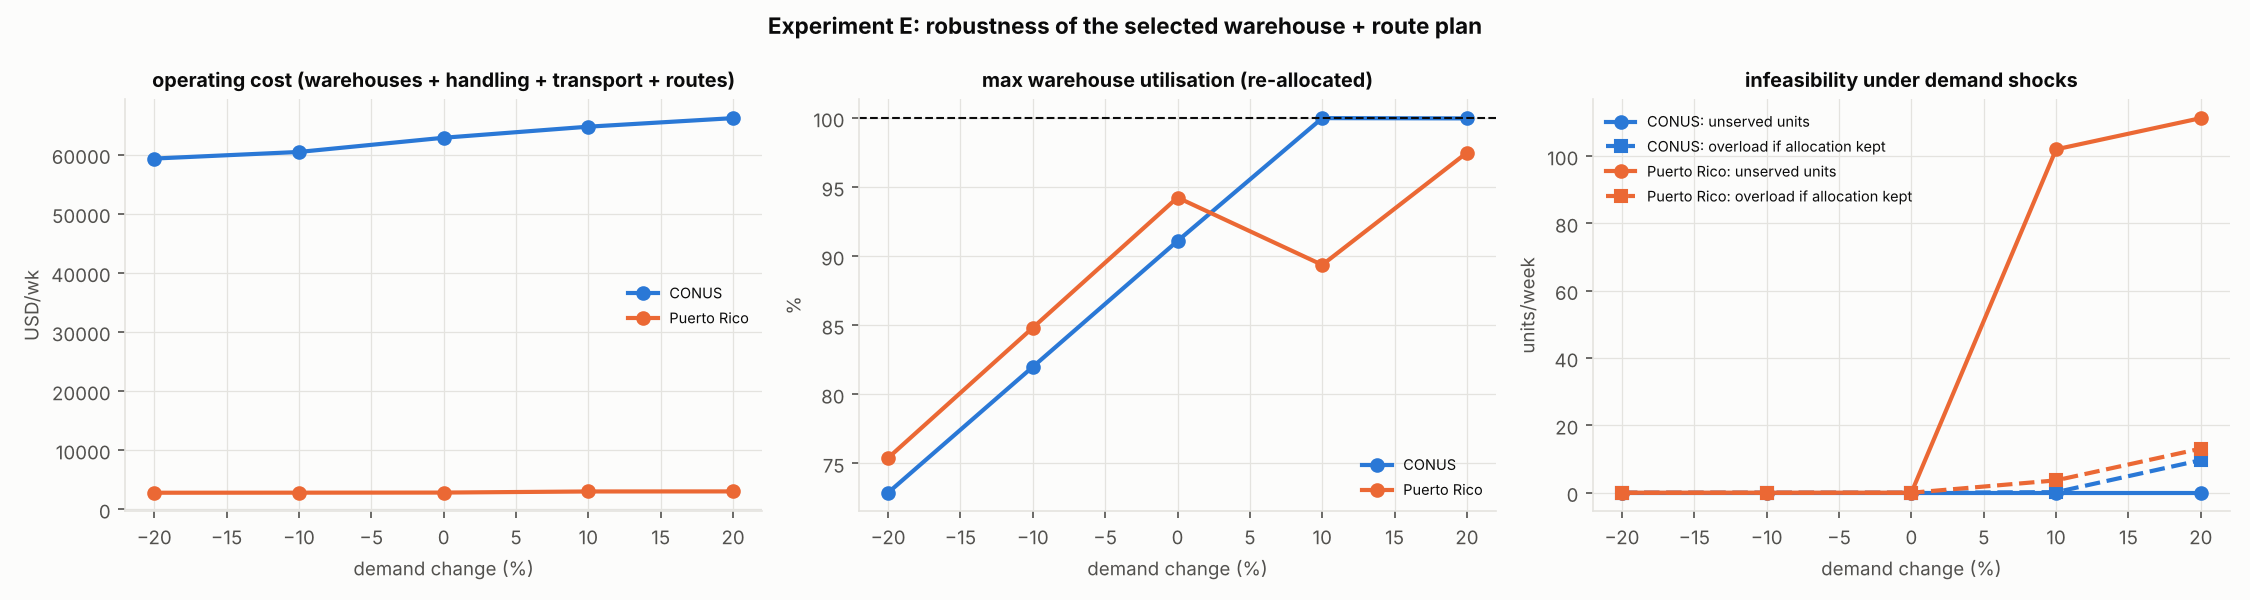

In [3]:
for f in ['phase8_forecast_impact','phase8_sensitivity_warehouse','phase8_sensitivity_routing','phase8_robustness']:
    display(Image(f'reports/figures/{f}.png'))

In [4]:
display(pd.read_csv(OUT / 'consistency_checks.csv'))
display(pd.read_csv(OUT / 'final_performance_summary.csv'))

,check,passed,detail
0,every demand zone is allocated,True,"337 rows, 337 zones"
1,no closed warehouse serves demand,True,NaN
2,warehouse capacity respected (units/week),True,max utilisation 94.2%
3,zone and warehouse in the same network,True,NaN
4,vehicle capacity respected,True,max load 30 / 30
5,routes start and end at their depot,True,NaN
6,each stop is routed from the warehouse its zone is alloc...,True,NaN
7,stop network equals route network (no mainland-island ro...,True,NaN
8,no stop visited twice,True,NaN
9,CONUS: all forecast packages routed (largest-remainder r...,True,278 vs 278


,section,network,metric,value,unit,source,baseline,improvement_pct
0,data,ALL,raw order-item rows,180519,rows,actual,NaN,NaN
1,data,ALL,orders in demand set,62011,orders,actual,NaN,NaN
2,data,ALL,units in demand set,361965,units,actual,NaN,NaN
3,forecast,CONUS,demand zones,312,zones,actual,NaN,NaN
4,forecast,CONUS,forecast orders per week,279.5,orders/week,forecast,NaN,NaN
5,forecast,CONUS,forecast units per week,297.80760476515593,units/week,forecast,NaN,NaN
6,forecast,Puerto Rico,demand zones,25,zones,actual,NaN,NaN
7,forecast,Puerto Rico,forecast orders per week,175.5,orders/week,forecast,NaN,NaN
8,forecast,Puerto Rico,forecast units per week,175.5,units/week,forecast,NaN,NaN
9,forecast,CONUS,orders model,share_x_recent_level (regime_reset),NaN,forecast,NaN,NaN
